# Contralesional Motor-Intent Decoding after Stroke
## Notebook 02 · Group analysis: eight research questions (47 patients)

*Case study: EEG pipeline for an IpsiHand-type contralesional BCI · November 2026*

### Executive summary
- **Data quality:** 47 of 50 recordings are usable. The 3 failures are white-noise recordings, detected automatically by the aperiodic-slope check.
- **Physiology:** 91% of patients show μ/β ERD at the healthy-hemisphere C electrode during affected-hand imagery. Its lateralisation follows the imagined hand rather than the lesion (control analysis, Q2).
- **Electrode count:** for a single control channel, the reference montage makes no significant difference (Friedman p = 0.51). The same 6 electrodes used as features raise AUC from 0.60 to 0.70.
- **Signal design:** a broad 8–30 Hz band beats a patient-specific 1-Hz bin with ~20 calibration trials. ~1 s AR windows beat 0.5 s windows. 125 Hz sampling is sufficient.
- **Confounds:** in this paradigm, EOG channels alone decode MI-vs-rest (AUC 0.74) better than sensorimotor channels (0.67). With confounds matched, only the sensorimotor channels carry information (Q8).

All numbers come from `scripts/run_group_analysis.py` and `scripts/run_confound_check.py`; this notebook only loads, tests and plots them.

| # | Question | Why Kandu cares |
|---|---|---|
| Q1 | Which recordings, channels and trials are usable? | automatic QC for home use |
| Q2 | Is there an ERD over the **healthy** hemisphere when patients imagine moving the **affected** hand? | the physiological premise of the device |
| Q3 | How well does **one** healthy-side electrode decode intent, and which **reference** (how many helper electrodes) works best? | "can we drop electrodes?" |
| Q4 | Does a data-driven channel subset beat the fixed montage? AUC vs number of channels | headset design |
| Q5 | Which **frequency** carries the signal? Patient-specific bin vs fixed band | calibration design |
| Q6 | **Window length** (latency) vs accuracy; AR vs FFT; **sampling rate** | embedded compute and closed-loop latency |
| Q7 | Does decodability track **clinical** scores (NIHSS, MBI, mRS, time since stroke, cortical lesion)? | patient selection / screening |

**Statistics.** With n ≈ 47 patients and non-Gaussian AUCs we use non-parametric tests: Wilcoxon signed-rank (paired), Friedman (several pipelines), Spearman ρ (correlations), Mann-Whitney U (groups). Pairwise families get a **Holm** correction. Per-patient decoding significance uses a **permutation test** (200 label swaps within trials, so the null distribution keeps the CV structure).

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src")); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, mne
from scipy import stats
from kandu_eeg import config as C, io, viz as V
mne.set_log_level("ERROR"); V.set_style()
R = C.RESULTS_DIR
part = io.load_participants()
qc = pd.read_csv(R / "qc_summary.csv"); auc = pd.read_csv(R / "decoding_auc.csv"); perm = pd.read_csv(R / "permutation.csv")

def holm(p):
    p = np.asarray(p); o = np.argsort(p); m = len(p); adj = np.empty(m)
    adj[o] = np.minimum(1, np.maximum.accumulate((m - np.arange(m)) * p[o])); return adj

def boot_ci(x, n=5000, seed=0):
    rng = np.random.default_rng(seed); x = np.asarray(x)
    b = rng.choice(x, (n, len(x))).mean(1); return np.percentile(b, [2.5, 97.5])

## Q1 · Data quality

recordings: 50 total, 47 usable, dead (white-noise, slope > -0.3): [5, 15, 49]
bad channels per usable recording: median 2, max 9
trials kept (150 µV p-p on sensorimotor channels): median 39/40, min 21; affected-hand trials median 19/20


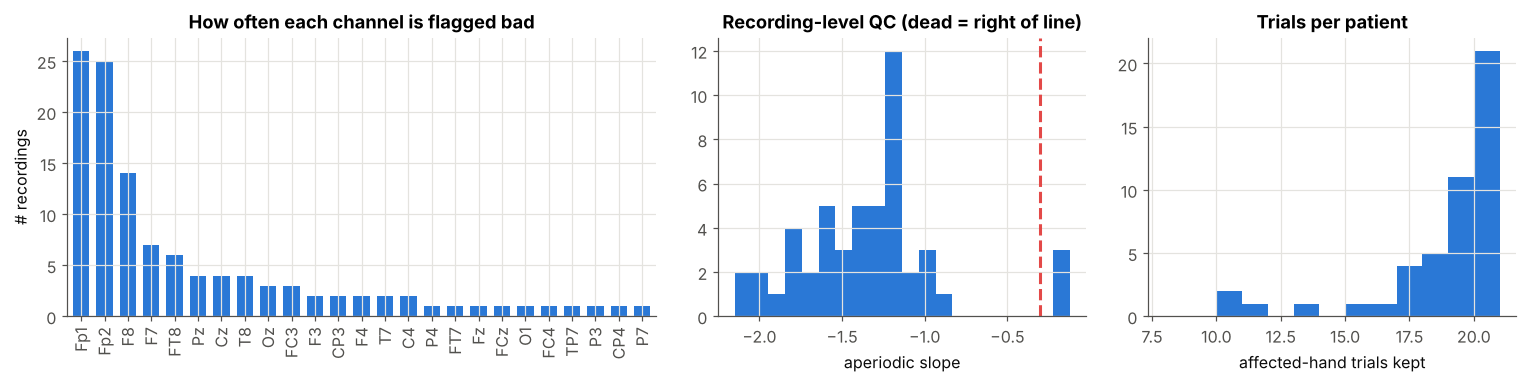

In [2]:
usable = qc[qc.usable]
print(f"recordings: {len(qc)} total, {len(usable)} usable, dead (white-noise, slope > {C.MIN_APERIODIC_SLOPE}): {qc.loc[~qc.usable, 'subject'].tolist()}")
print(f"bad channels per usable recording: median {usable.n_bad_channels.median():.0f}, max {usable.n_bad_channels.max():.0f}")
print(f"trials kept (150 µV p-p on sensorimotor channels): median {usable.n_trials_kept.median():.0f}/40, min {usable.n_trials_kept.min():.0f}; affected-hand trials median {usable.n_aff_kept.median():.0f}/20")
bad_counts = pd.Series([c for s in usable.bad_channels.dropna() for c in s.split(",")]).value_counts()
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6), gridspec_kw=dict(width_ratios=[1.6, 1, 1]))
bad_counts.plot.bar(ax=ax[0], color=V.SERIES[0], width=.7); ax[0].set_ylabel("# recordings"); ax[0].set_title("How often each channel is flagged bad")
ax[1].hist(qc.aperiodic_slope, bins=20, color=V.SERIES[0]); ax[1].axvline(C.MIN_APERIODIC_SLOPE, color=V.SERIES[7], ls="--")
ax[1].set_xlabel("aperiodic slope"); ax[1].set_title("Recording-level QC (dead = right of line)")
ax[2].hist(usable.n_aff_kept, bins=range(8, 22), color=V.SERIES[0]); ax[2].set_xlabel("affected-hand trials kept"); ax[2].set_title("Trials per patient")
plt.tight_layout(); plt.show()

Frontal-pole (Fp1/Fp2) and lateral frontal/temporal channels fail most often: eye and muscle artefacts plus poor contact on the forehead or hair line. **Central channels, the ones a Kandu headset uses, are rarely bad.**

## Q2 · Is there a contralesional ERD for affected-hand imagery?
Every patient is **mirrored** so the healthy (contralesional, CL) hemisphere is the same for everyone. Time courses: CAR-29, Pfurtscheller ERD% relative to −1.5 to −0.5 s, mean ± SEM across patients.

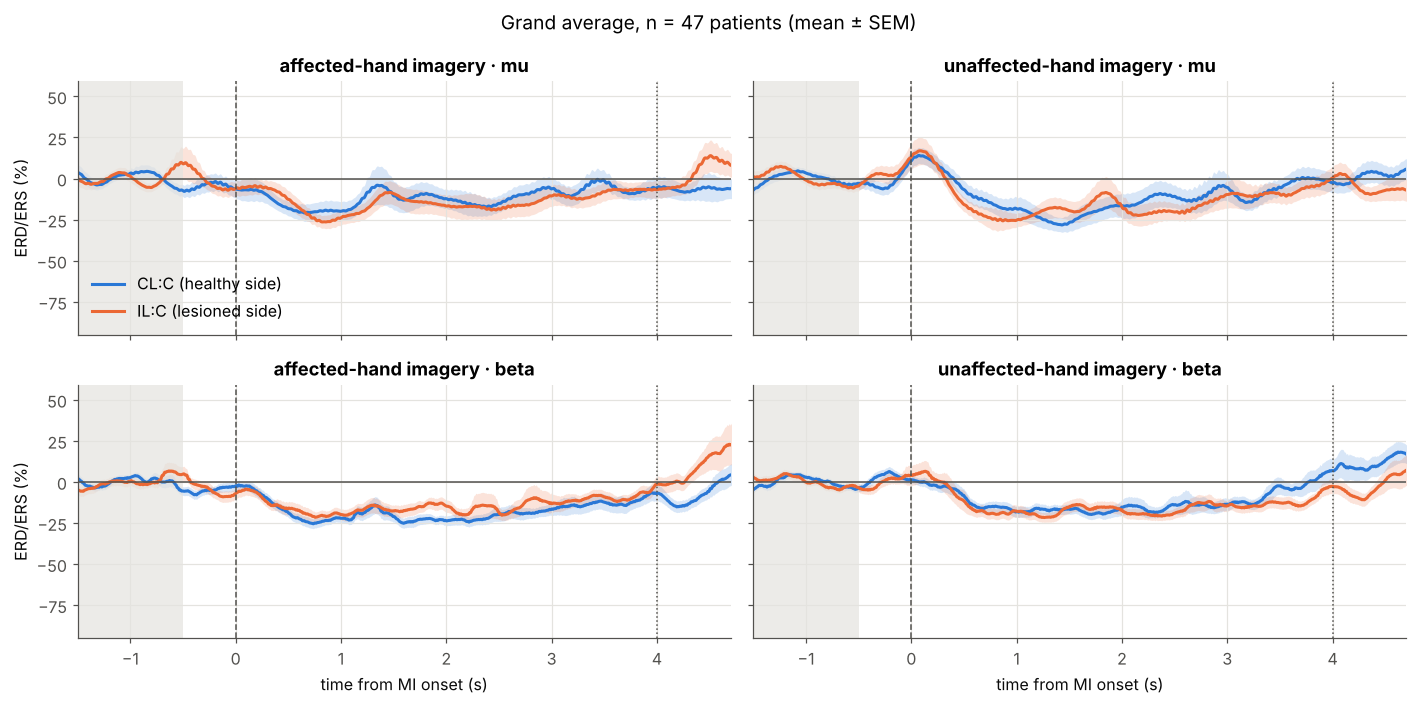

In [3]:
E = np.load(R / "erd_timecourses.npz")
t = np.linspace(C.EPOCH_TMIN, C.EPOCH_TMAX, E["affected_mu"].shape[-1])
fig, axs = plt.subplots(2, 2, figsize=(13, 6.5), sharex=True, sharey=True)
for col, hand in enumerate(["affected", "unaffected"]):
    for row, b in enumerate(["mu", "beta"]):
        a = axs[row, col]; d = E[f"{hand}_{b}"]                   # (n, 2 [CL, IL], time)
        for k, (lab, colr) in enumerate([("CL:C (healthy side)", V.CL_COLOR), ("IL:C (lesioned side)", V.IL_COLOR)]):
            m, se = d[:, k].mean(0), d[:, k].std(0) / np.sqrt(len(d))
            a.plot(t, m, color=colr, label=lab); a.fill_between(t, m - se, m + se, color=colr, alpha=.18, lw=0)
        a.axhline(0, color=V.INK2, lw=1); a.axvspan(*C.ERD_REF_WIN, color=V.GRID, alpha=.7, lw=0)
        a.axvline(0, color=V.INK2, ls="--", lw=1); a.axvline(4, color=V.INK2, ls=":", lw=1); a.set_xlim(-1.5, 4.7)
        a.set_title(f"{hand}-hand imagery · {b}")
axs[0, 0].legend(loc="lower left"); [a.set_ylabel("ERD/ERS (%)") for a in axs[:, 0]]; [a.set_xlabel("time from MI onset (s)") for a in axs[1]]
fig.suptitle(f"Grand average, n = {len(d)} patients (mean ± SEM)"); plt.tight_layout(); plt.show()

In [4]:
erd = pd.read_csv(R / "erd_db.csv")
rows = []
for hand in ["affected", "unaffected"]:
    cl, il = erd[f"{hand}_erd_db_CL"], erd[f"{hand}_erd_db_IL"]
    rows.append(dict(imagery=hand, median_CL_dB=cl.median(), p_CL_vs_0=stats.wilcoxon(cl).pvalue, pct_patients_CL_ERD=(cl < 0).mean()*100,
                     median_IL_dB=il.median(), p_IL_vs_0=stats.wilcoxon(il).pvalue, p_CL_vs_IL=stats.wilcoxon(cl, il).pvalue))
q2 = pd.DataFrame(rows).set_index("imagery"); display(q2.round(4))
# Interaction: does the hemisphere difference depend on WHICH hand is imagined?
da = erd.affected_erd_db_CL - erd.affected_erd_db_IL; du = erd.unaffected_erd_db_CL - erd.unaffected_erd_db_IL
print(f"(CL-IL) affected-hand MI median {da.median():+.2f} dB | unaffected-hand MI {du.median():+.2f} dB | hand x hemisphere interaction Wilcoxon p = {stats.wilcoxon(da, du).pvalue:.4f}")

,median_CL_dB,p_CL_vs_0,pct_patients_CL_ERD,median_IL_dB,p_IL_vs_0,p_CL_vs_IL
imagery,,,,,,
affected,-1.1612,0.0,91.4894,-0.8343,0.0,0.0229
unaffected,-0.7251,0.0,78.7234,-0.7848,0.0,0.1070


(CL-IL) affected-hand MI median -0.27 dB | unaffected-hand MI +0.31 dB | hand x hemisphere interaction Wilcoxon p = 0.0030


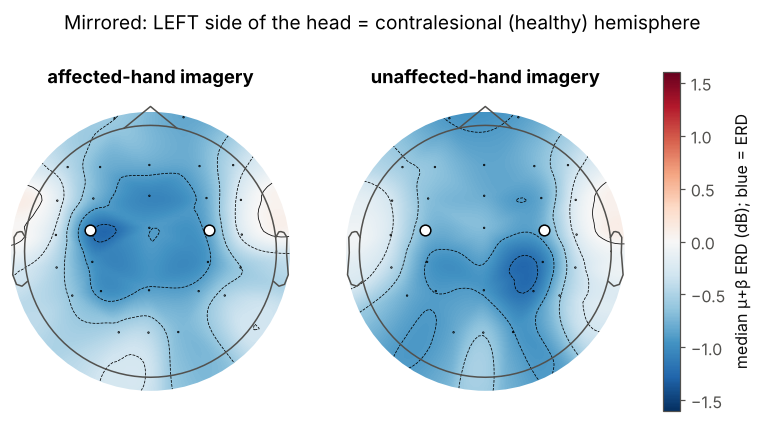

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(9, 4))
for a, hand in zip(axs, ["affected", "unaffected"]):
    topo = pd.read_csv(R / f"erd_topo_{hand}_mirrored.csv").drop(columns="subject").median()
    im = V.topomap(topo.to_dict(), a, vlim=(-1.6, 1.6), title=f"{hand}-hand imagery", mask_chs=["C3", "C4"])
plt.colorbar(im, ax=axs, label="median μ+β ERD (dB); blue = ERD")
fig.suptitle("Mirrored: LEFT side of the head = contralesional (healthy) hemisphere", y=1.02); plt.show()

**Answer Q2: yes, but read the control before concluding.** During affected-hand imagery, 91% of patients show ERD at the healthy-side C electrode (median −1.16 dB, Wilcoxon p < 10⁻⁹), and it is **stronger than at the lesioned-side homologue** (−0.83 dB, p = 0.023). The mirrored map shows the peak right at CL:C.

**The critical control:** the hemisphere difference **reverses for the unaffected hand** (CL−IL = −0.27 dB vs +0.31 dB; hand × hemisphere interaction p = 0.003). In both cases ERD is stronger over the hemisphere *ipsilateral to the imagined hand*. Healthy motor imagery is classically **contralateral**, and a lesion cannot explain the pattern for the healthy hand. So this is **not** clean evidence of lesion-driven ipsilateral recruitment. Candidate explanations to check *before* building on it: (i) a left/right label convention in the dataset (verify the trigger coding with the authors), (ii) a lateralised visual/mirror-neuron effect of the gripping video, (iii) genuinely bilateral or ipsilateral organisation in acute patients. Kandu's own data (attempted movement, no video) is the right place to test the premise.

**But note the topography:** the decrease is widespread, including frontal and occipital sites. Part of the "MI vs rest" contrast is not motor: during MI the patient watches a gripping *video*, during "rest" a static cue picture. Watching blocks occipital α, and the eyes behave differently. Q8 tests this directly.

## Q3 · One electrode on the healthy side: how good is it, and which reference?
Decoder = the IpsiHand-like rule: one control channel (CL:C), one patient-specific 1-Hz bin chosen on training folds among ERD bins, 1-feature LDA. Only the **derivation**, i.e. what we subtract and therefore how many electrodes we need, varies:

`raw` C−CPz (2 el.) · `bip_cp` C−CP (2) · `bip_fc` C−FC (2) · `lap4` C − mean(FC, CP, T, Cz) (5) · `car6` Kandu-like (6) · `car8` Bundy-2017 montage (8) · `car29` full cap (29)

In [6]:
aff = auc[auc.hand == "affected"]
single = aff[aff.pipeline.str.endswith("_bestbin") & (aff.site == "CL:C")].copy()
single["derivation"] = single.pipeline.str.replace("single_", "").str.replace("_bestbin", "")
order = ["raw", "bip_cp", "bip_fc", "lap4", "car6", "car8", "car29"]
W = single.pivot(index="subject", columns="derivation", values="auc")[order]
multi = aff[aff.site == "multi"].pivot(index="subject", columns="pipeline", values="auc")
summary = pd.DataFrame({"n_electrodes": [2, 2, 2, 5, 6, 8, 29] + [6, 6, 29, 29],
                        "mean_AUC": list(W.mean()) + list(multi[["kandu6_bandpower_lda", "kandu6_tangent_space", "all29_csp_lda", "all29_tangent_space"]].mean()),
                        "median_AUC": list(W.median()) + list(multi[["kandu6_bandpower_lda", "kandu6_tangent_space", "all29_csp_lda", "all29_tangent_space"]].median())},
                       index=[f"1 ch · {o}" for o in order] + ["kandu6 band-power LDA", "kandu6 tangent space", "29 ch CSP+LDA", "29 ch tangent space"])
summary["95% CI"] = [tuple(np.round(boot_ci(c), 3)) for c in [W[o] for o in order] + [multi[k] for k in ["kandu6_bandpower_lda", "kandu6_tangent_space", "all29_csp_lda", "all29_tangent_space"]]]
print("Friedman across the 7 single-channel derivations: chi2 = %.2f, p = %.4g" % stats.friedmanchisquare(*[W[o] for o in order]))
summary.round(3)

Friedman across the 7 single-channel derivations: chi2 = 5.30, p = 0.5061


,n_electrodes,mean_AUC,median_AUC,95% CI
1 ch · raw,2,0.557,0.543,"(0.523, 0.591)"
1 ch · bip_cp,2,0.577,0.570,"(0.541, 0.613)"
1 ch · bip_fc,2,0.594,0.575,"(0.554, 0.636)"
1 ch · lap4,5,0.589,0.585,"(0.555, 0.625)"
1 ch · car6,6,0.597,0.570,"(0.56, 0.636)"
1 ch · car8,8,0.596,0.575,"(0.562, 0.631)"
1 ch · car29,29,0.568,0.570,"(0.532, 0.604)"
kandu6 band-power LDA,6,0.696,0.708,"(0.662, 0.729)"
kandu6 tangent space,6,0.712,0.738,"(0.665, 0.757)"
29 ch CSP+LDA,29,0.709,0.724,"(0.663, 0.752)"


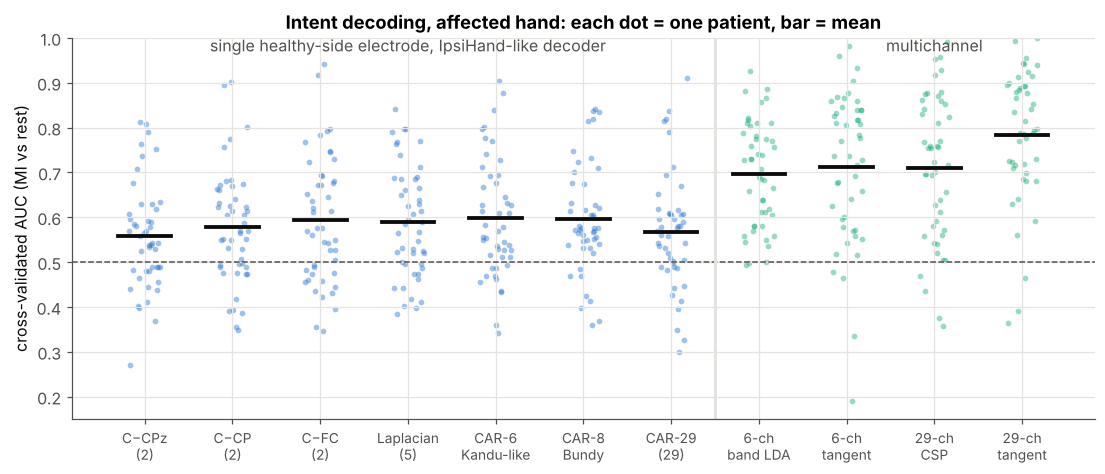

In [7]:
fig, ax = plt.subplots(figsize=(12, 4.5))
cols = order + ["kandu6_bandpower_lda", "kandu6_tangent_space", "all29_csp_lda", "all29_tangent_space"]
data = pd.concat([W, multi], axis=1)[cols]
labels = ["C−CPz\n(2)", "C−CP\n(2)", "C−FC\n(2)", "Laplacian\n(5)", "CAR-6\nKandu-like", "CAR-8\nBundy", "CAR-29\n(29)", "6-ch\nband LDA", "6-ch\ntangent", "29-ch\nCSP", "29-ch\ntangent"]
rng = np.random.default_rng(0)
for i, c in enumerate(cols):
    y = data[c].values; ax.scatter(i + rng.uniform(-.18, .18, len(y)), y, s=14, color=V.SERIES[0] if i < 7 else V.SERIES[2], alpha=.45, lw=0)
    ax.plot([i - .3, i + .3], [np.mean(y)] * 2, color=V.INK, lw=2.5)
ax.axhline(.5, color=V.INK2, ls="--", lw=1); ax.axvline(6.5, color=V.GRID, lw=2)
ax.text(3, .97, "single healthy-side electrode, IpsiHand-like decoder", ha="center", color=V.INK2); ax.text(9, .97, "multichannel", ha="center", color=V.INK2)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(labels, fontsize=9); ax.set_ylabel("cross-validated AUC (MI vs rest)"); ax.set_ylim(.15, 1.0)
ax.set_title("Intent decoding, affected hand: each dot = one patient, bar = mean"); plt.show()

In [8]:
# pairwise: each derivation vs CAR-6 (the Kandu-like baseline), Holm-corrected
rows = []
for o in order:
    if o == "car6": continue
    st = stats.wilcoxon(W[o], W["car6"]); rows.append(dict(derivation=o, mean_diff_vs_car6=(W[o] - W["car6"]).mean(), p=st.pvalue))
pw = pd.DataFrame(rows); pw["p_holm"] = holm(pw.p); print(pw.round(4).to_string(index=False))
# healthy vs lesioned hemisphere, same derivation
rows = []
for o in order:
    a = aff[(aff.pipeline == f"single_{o}_bestbin")].pivot(index="subject", columns="site", values="auc")
    rows.append(dict(derivation=o, CL=a["CL:C"].mean(), IL=a["IL:C"].mean(), p=stats.wilcoxon(a["CL:C"], a["IL:C"]).pvalue))
hemi_tab = pd.DataFrame(rows); hemi_tab["p_holm"] = holm(hemi_tab.p); print("\nhealthy (CL) vs lesioned (IL) C electrode:"); print(hemi_tab.round(4).to_string(index=False))

derivation  mean_diff_vs_car6      p  p_holm
       raw            -0.0401 0.1609  0.9652
    bip_cp            -0.0199 0.5186  1.0000
    bip_fc            -0.0035 0.7995  1.0000
      lap4            -0.0080 0.4094  1.0000
      car8            -0.0016 0.9199  1.0000
     car29            -0.0294 0.1931  0.9656

healthy (CL) vs lesioned (IL) C electrode:
derivation     CL     IL      p  p_holm
       raw 0.5571 0.5901 0.1755     1.0
    bip_cp 0.5773 0.5842 0.7549     1.0
    bip_fc 0.5937 0.6086 0.7472     1.0
      lap4 0.5892 0.5813 0.7019     1.0
      car6 0.5972 0.5851 0.6798     1.0
      car8 0.5957 0.5763 0.2698     1.0
     car29 0.5678 0.5911 0.2380     1.0


In [9]:
sig = perm.p_car6 < 0.05
print(f"CAR-6 IpsiHand-like decoder: {sig.sum()}/{len(perm)} patients ({sig.mean()*100:.0f}%) above chance (permutation p < 0.05; ~5% expected by chance alone)")
print(f"mean AUC in significant patients = {perm.auc_car6[sig].mean():.3f}")
best = pd.concat([W, multi], axis=1).max(axis=1)
print(f"patients with AUC >= 0.70 for at least one pipeline: {(best >= .7).sum()}  (note: max over 11 pipelines is optimistic)")

CAR-6 IpsiHand-like decoder: 8/47 patients (17%) above chance (permutation p < 0.05; ~5% expected by chance alone)
mean AUC in significant patients = 0.808
patients with AUC >= 0.70 for at least one pipeline: 45  (note: max over 11 pipelines is optimistic)


**Answer Q3.**
1. With **one** healthy-side electrode and the IpsiHand-like decoder, mean AUC is only **0.56–0.60**, and **the reference makes no significant difference** (Friedman p = 0.51; every pairwise Holm p > 0.9). A 2-electrode bipolar C−FC (0.594) is statistically as good as CAR-6 (0.597) or CAR-8 (0.596). **On this evidence, the 5 "noise" electrodes do not buy accuracy for a single control channel.**
2. Only 8/47 patients (17%) are individually above chance with that decoder (5% expected by chance), but those 8 are good (mean AUC 0.81). That matches the clinical reality that IpsiHand screens patients first.
3. **Using the same 6 electrodes as features, not as a reference, gives the largest gain**: 0.597 → **0.70** (band-power LDA) / 0.71 (tangent space). Same hardware, better software.
4. The 29-channel models reach 0.78, but Q8 shows that much of that comes from eye/visual confounds, not motor cortex.
5. Healthy vs lesioned C electrode: no difference in decodability (all p > 0.2). In acute patients both hemispheres carry the signal.

## Q4 · How many channels, and which ones? (data-driven)
**Greedy forward selection, nested in CV**: on each training fold, add the channel (log μ / low-β / high-β power after CAR-29) that most improves inner-CV AUC, then score the selected set on the held-out fold. The selection never sees test data. Channel names are lesion-relative (`CL:` healthy side, `IL:` lesioned side).

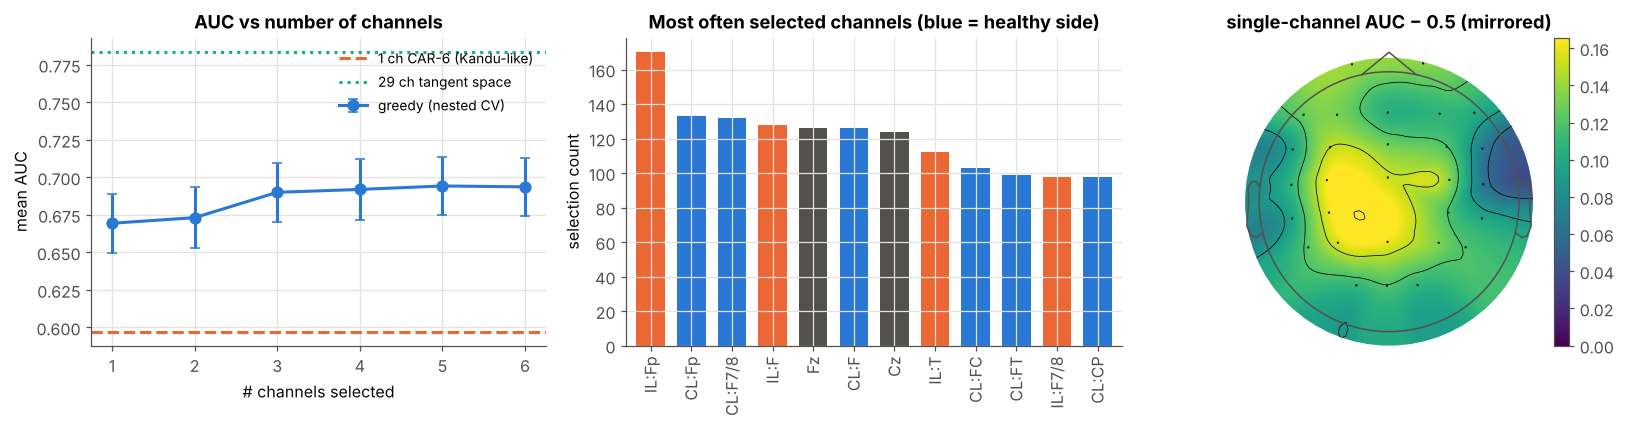

first channel picked (per patient):
first_pick
IL:Fp      6
IL:T       5
Cz         5
Pz         3
IL:P7/8    2
FCz        2
CL:P       2
CL:FC      2

k=1 vs k=6 Wilcoxon p = 0.0587


In [10]:
g = pd.read_csv(R / "greedy_selection.csv"); ks = [f"k{i}" for i in range(1, 7)]
fig, ax = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw=dict(width_ratios=[1.1, 1.2, 1]))
m, se = g[ks].mean(), g[ks].std() / np.sqrt(len(g))
ax[0].errorbar(range(1, 7), m, yerr=se, color=V.SERIES[0], marker="o", ms=7, capsize=3, label="greedy (nested CV)")
ax[0].axhline(W["car6"].mean(), color=V.SERIES[1], ls="--", label="1 ch CAR-6 (Kandu-like)")
ax[0].axhline(multi["all29_tangent_space"].mean(), color=V.SERIES[2], ls=":", label="29 ch tangent space")
ax[0].set_xlabel("# channels selected"); ax[0].set_ylabel("mean AUC"); ax[0].legend(fontsize=9); ax[0].set_title("AUC vs number of channels")
counts = pd.read_csv(R / "greedy_counts.csv").drop(columns="subject").sum().sort_values(ascending=False)
counts.head(12).plot.bar(ax=ax[1], color=[V.CL_COLOR if c.startswith("CL") else V.IL_COLOR if c.startswith("IL") else V.INK2 for c in counts.head(12).index], width=.7)
ax[1].set_title("Most often selected channels (blue = healthy side)"); ax[1].set_ylabel("selection count")
sm = pd.read_csv(R / "single_channel_auc_mirrored.csv").drop(columns="subject").mean()
im = V.topomap((sm - .5).to_dict(), ax[2], cmap="viridis", vlim=(0, (sm - .5).max()), title="single-channel AUC − 0.5 (mirrored)")
plt.colorbar(im, ax=ax[2]); plt.tight_layout(); plt.show()
print("first channel picked (per patient):"); print(g.first_pick.value_counts().head(8).to_string())
print("\nk=1 vs k=6 Wilcoxon p =", round(stats.wilcoxon(g.k1, g.k6).pvalue, 4))

**Answer Q4.** Data-driven selection plateaus at about **3 channels** (0.67 → 0.69; 1 vs 6 channels p = 0.06). The channels it picks most are a warning, though: **IL:Fp, CL:Fp, F7/F8**, i.e. eye and forehead sites. An unconstrained selector chases the ocular confound. The single-channel AUC map (right), which is less prone to it, peaks over **central / fronto-central cortex, biased to the healthy side**, i.e. where a Kandu headset sits. Lesson for headset design: **constrain the candidate set to sensorimotor sites and validate against an EOG-only baseline** before trusting any channel ranking.

## Q5 · Which frequency?
For each patient: the 1-Hz bin with the strongest ERD (most negative r², CL:C, CAR-6), on all trials. It is descriptive only, since the decoders above choose it inside CV. Bundy et al. (2017) reported control frequencies of 9–19 Hz in chronic patients.

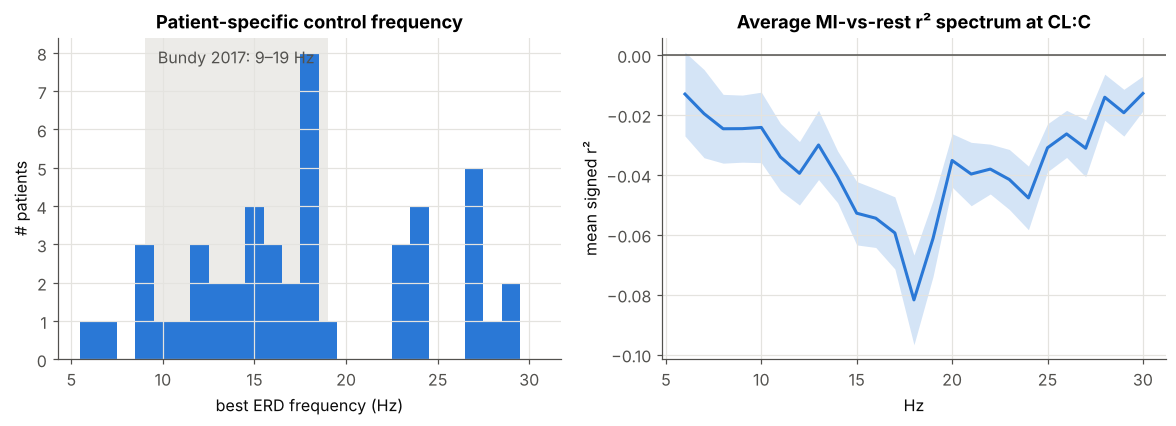

in 9–19 Hz: 64% of patients; median = 18 Hz
patient-specific bin AUC 0.597 vs fixed 8–30 Hz band 0.649  (Wilcoxon p = 0.0129)


In [11]:
bf = pd.read_csv(R / "best_frequency.csv"); r2s = np.load(R / "r2_spectra.npy"); fr = np.arange(6, 31)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].hist(bf.best_freq, bins=np.arange(5.5, 31.5, 1), color=V.SERIES[0]); ax[0].axvspan(9, 19, color=V.GRID, alpha=.7, lw=0, zorder=0)
ax[0].text(14, ax[0].get_ylim()[1]*.92, "Bundy 2017: 9–19 Hz", ha="center", color=V.INK2); ax[0].set_xlabel("best ERD frequency (Hz)"); ax[0].set_ylabel("# patients")
ax[0].set_title("Patient-specific control frequency")
ax[1].plot(fr, r2s.mean(0), color=V.SERIES[0]); ax[1].fill_between(fr, r2s.mean(0) - r2s.std(0)/np.sqrt(len(r2s)), r2s.mean(0) + r2s.std(0)/np.sqrt(len(r2s)), color=V.SERIES[0], alpha=.2, lw=0)
ax[1].axhline(0, color=V.INK2, lw=1); ax[1].set_xlabel("Hz"); ax[1].set_ylabel("mean signed r²"); ax[1].set_title("Average MI-vs-rest r² spectrum at CL:C")
plt.show()
fixed = aff[(aff.pipeline == "single_car6_mubeta") & (aff.site == "CL:C")].set_index("subject").auc
print(f"in 9–19 Hz: {((bf.best_freq >= 9) & (bf.best_freq <= 19)).mean()*100:.0f}% of patients; median = {bf.best_freq.median():.0f} Hz")
print(f"patient-specific bin AUC {W['car6'].mean():.3f} vs fixed 8–30 Hz band {fixed.mean():.3f}  (Wilcoxon p = {stats.wilcoxon(W['car6'], fixed.loc[W.index]).pvalue:.4f})")

**Answer Q5.** Patient-specific best frequencies spread across 6–30 Hz (median **18 Hz**, 64% inside Bundy's 9–19 Hz range): mostly **β**, not μ. But with ~20 calibration trials, picking one 1-Hz bin **overfits**: a **fixed 8–30 Hz band beats the patient-specific bin** (AUC 0.649 vs 0.597, p = 0.013). Recommendation: start from a broad μ+β band and narrow to a patient-specific band only once enough calibration data exist (e.g. accumulated across days), or regularise the choice (a filter bank plus shrinkage).

## Q6 · Latency and compute: window length, AR vs FFT, sampling rate

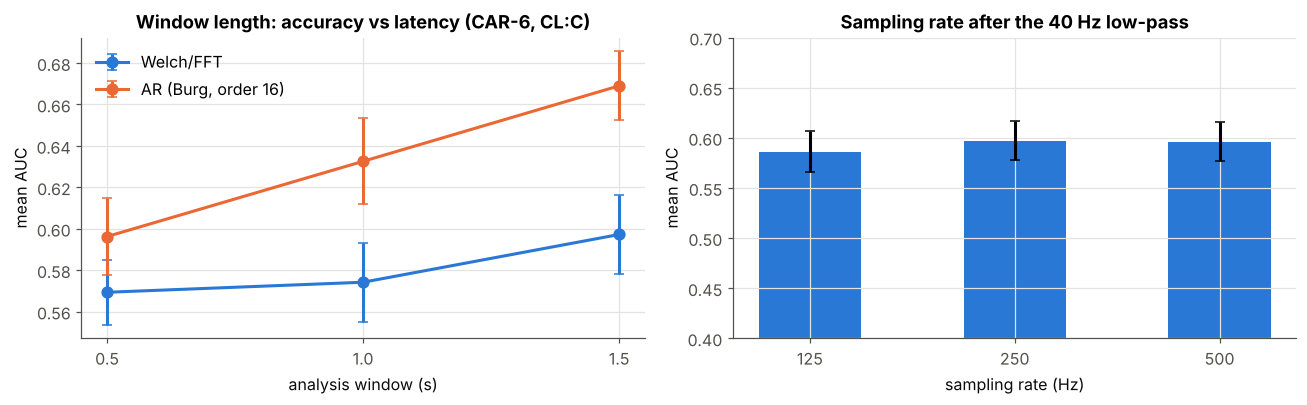

AR vs Welch, Wilcoxon per window: {0.5: np.float64(0.078), 1.0: np.float64(0.0063), 1.5: np.float64(0.0002)}
AR 0.5 s vs 1.5 s p = 0.0014


125 vs 250 Hz p = 0.495 | 250 vs 500 Hz p = 0.381


In [12]:
wl = pd.read_csv(R / "window_length.csv"); sr = pd.read_csv(R / "sampling_rate.csv")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for i, psd in enumerate(["welch", "ar"]):
    d = wl[wl.psd == psd].groupby("window_s").auc; ax[0].errorbar(d.mean().index, d.mean(), yerr=d.std()/np.sqrt(d.count()), marker="o", ms=7, capsize=3, color=V.SERIES[i], label={"welch": "Welch/FFT", "ar": "AR (Burg, order 16)"}[psd])
ax[0].set_xlabel("analysis window (s)"); ax[0].set_ylabel("mean AUC"); ax[0].legend(); ax[0].set_title("Window length: accuracy vs latency (CAR-6, CL:C)"); ax[0].set_xticks([.5, 1, 1.5])
d = sr.groupby("sfreq").auc; ax[1].bar([str(int(s)) for s in d.mean().index], d.mean(), yerr=d.std()/np.sqrt(d.count()), color=V.SERIES[0], width=.5, capsize=3)
ax[1].set_ylim(.4, .7); ax[1].set_xlabel("sampling rate (Hz)"); ax[1].set_ylabel("mean AUC"); ax[1].set_title("Sampling rate after the 40 Hz low-pass")
plt.tight_layout(); plt.show()
p = wl.pivot_table(index=["subject", "window_s"], columns="psd", values="auc")
print("AR vs Welch, Wilcoxon per window:", {w: round(stats.wilcoxon(p.xs(w, level=1).ar, p.xs(w, level=1).welch).pvalue, 4) for w in [.5, 1., 1.5]})
q = wl[wl.psd == "ar"].pivot(index="subject", columns="window_s", values="auc"); print("AR 0.5 s vs 1.5 s p =", round(stats.wilcoxon(q[.5], q[1.5]).pvalue, 4))
s2 = sr.pivot(index="subject", columns="sfreq", values="auc"); print("125 vs 250 Hz p =", round(stats.wilcoxon(s2[125.], s2[250.]).pvalue, 3), "| 250 vs 500 Hz p =", round(stats.wilcoxon(s2[250.], s2[500.]).pvalue, 3))

**Answer Q6.**
- **Longer windows help:** AR AUC rises from 0.5 s to 1.5 s (p = 0.001). That is the latency/accuracy trade-off. A 1 s window, updated every 125 ms, is a reasonable compromise for a rehab orthosis (Hebbian pairing tolerates a few hundred ms).
- **AR beats Welch** at 1.0 s and 1.5 s (p = 0.006, p = 0.0002) and is no worse at 0.5 s: it supports the BCI2000/IpsiHand choice of maximum-entropy spectra.
- **Sampling rate is irrelevant** once low-passed at 40 Hz (125 vs 250 Hz p = 0.50; 250 vs 500 Hz p = 0.38). Running at **125 Hz** cuts compute and battery by 4× with no loss.

## Q7 · Does decodability relate to clinical status?
**NIHSS**: stroke severity (0–42, higher = worse). **MBI**: Modified Barthel Index of daily-living independence (0–100, higher = better). **mRS**: modified Rankin Scale of disability (0–5, higher = worse). **Duration**: days since stroke.

rho                      p_holm                   
outcome  auc_car6 auc_ts29 erd_CL_dB auc_car6 auc_ts29 erd_CL_dB
clinical                                                        
Age        -0.110   -0.149     0.039    1.000      1.0       1.0
Duration    0.318    0.168    -0.049    0.437      1.0       1.0
MBI         0.072   -0.068    -0.043    1.000      1.0       1.0
NIHSS      -0.018    0.022    -0.047    1.000      1.0       1.0
mRS        -0.019    0.006     0.197    1.000      1.0       1.0

auc_car6: cortical lesion (n=9) 0.624 vs subcortical (n=38) 0.591, Mann-Whitney p = 0.543
auc_ts29: cortical lesion (n=9) 0.737 vs subcortical (n=38) 0.795, Mann-Whitney p = 0.190


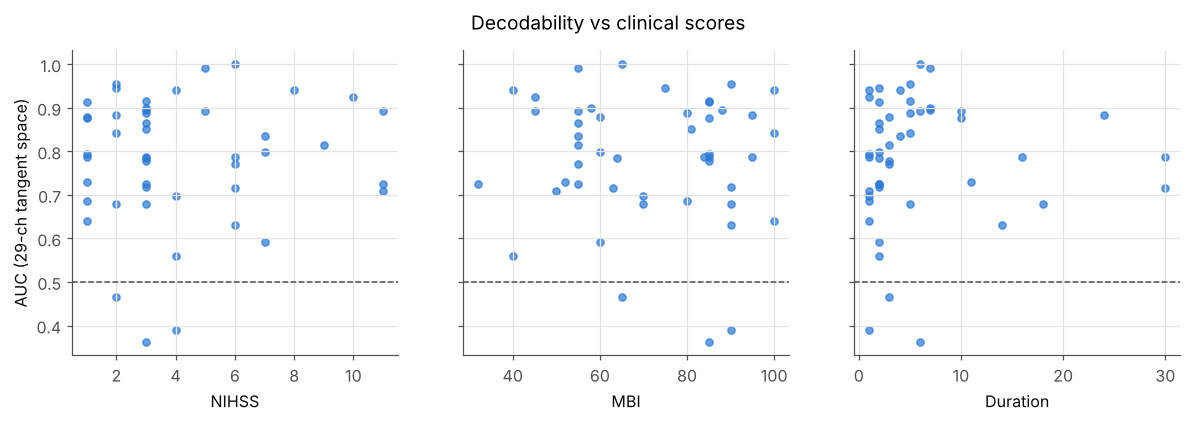

In [13]:
df = part.join(W["car6"].rename("auc_car6")).join(multi["all29_tangent_space"].rename("auc_ts29")).join(erd.set_index("subject")["affected_erd_db_CL"].rename("erd_CL_dB")).dropna(subset=["auc_car6"])
rows = []
for y in ["auc_car6", "auc_ts29", "erd_CL_dB"]:
    for x in ["NIHSS", "MBI", "mRS", "Duration", "Age"]:
        rho, p = stats.spearmanr(df[x], df[y]); rows.append(dict(outcome=y, clinical=x, rho=rho, p=p))
cor = pd.DataFrame(rows); cor["p_holm"] = holm(cor.p); display(cor.round(3).pivot(index="clinical", columns="outcome", values=["rho", "p_holm"]))
for y in ["auc_car6", "auc_ts29"]:
    a, b = df.loc[df.cortical_lesion, y], df.loc[~df.cortical_lesion, y]
    print(f"{y}: cortical lesion (n={len(a)}) {a.mean():.3f} vs subcortical (n={len(b)}) {b.mean():.3f}, Mann-Whitney p = {stats.mannwhitneyu(a, b).pvalue:.3f}")
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for a, x in zip(ax, ["NIHSS", "MBI", "Duration"]):
    a.scatter(df[x], df.auc_ts29, color=V.SERIES[0], s=22, alpha=.7); a.set_xlabel(x); a.axhline(.5, color=V.INK2, ls="--", lw=1)
ax[0].set_ylabel("AUC (29-ch tangent space)"); fig.suptitle("Decodability vs clinical scores"); plt.show()

**Answer Q7.** No clinical score predicts decodability or ERD strength after Holm correction. The strongest trend is **time since stroke** (ρ = 0.32 with single-channel AUC, uncorrected p = 0.03, Holm p = 0.44): decodability may improve as patients move out of the hyper-acute phase. That is a hypothesis worth testing in Kandu's longitudinal data. Cortical vs subcortical lesions: no difference (n = 9 vs 38). Clinical scores are therefore **not a substitute for an EEG screening session**.

## Q8 · Is the decoder reading motor cortex, or eyes and vision?
`scripts/run_confound_check.py` decodes with channel groups that cannot see the motor strip well: **EOG only** (HEOL, VEOR), **frontal pole** (Fp1 Fp2 F7 F8), **occipital** (O1 Oz O2 P7 P8), vs **sensorimotor** (FC3 C3 CP3 FC4 C4 CP4). Two tasks:
- **MI vs rest**: the device task, but video vs static picture differs too;
- **affected vs unaffected hand**, both within the MI window: same video, same timing, so eye and visual confounds **cancel**, and only *which hand* differs.

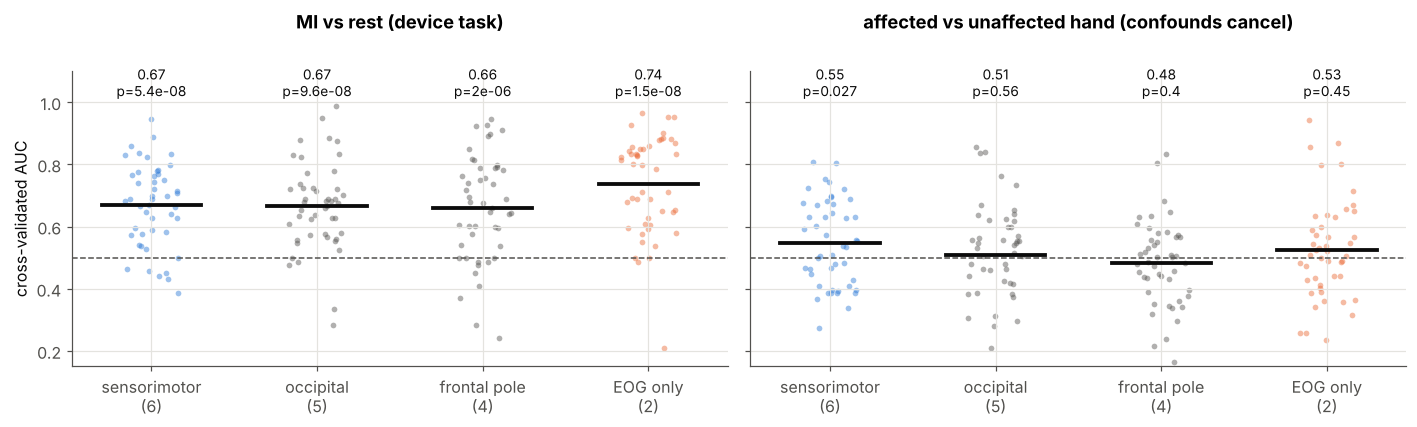

In [14]:
cc = pd.read_csv(R / "confound_check.csv")
groups = ["sensorimotor", "occipital", "frontal_pole", "eog"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a, task, ttl in [(ax[0], "mi_vs_rest", "MI vs rest (device task)"), (ax[1], "hand_vs_hand", "affected vs unaffected hand (confounds cancel)")]:
    w = cc[cc.task == task].pivot(index="subject", columns="group", values="auc")[groups]
    rng = np.random.default_rng(1)
    for i, g in enumerate(groups):
        a.scatter(i + rng.uniform(-.17, .17, len(w)), w[g], s=14, alpha=.45, lw=0, color=V.SERIES[0] if g == "sensorimotor" else V.SERIES[1] if g == "eog" else V.INK2)
        a.plot([i - .3, i + .3], [w[g].mean()] * 2, color=V.INK, lw=2.5)
        p = stats.wilcoxon(w[g] - .5).pvalue
        a.text(i, 1.02, f"{w[g].mean():.2f}\np={p:.2g}", ha="center", fontsize=9, color=V.INK)
    a.axhline(.5, color=V.INK2, ls="--", lw=1); a.set_xticks(range(4)); a.set_xticklabels(["sensorimotor\n(6)", "occipital\n(5)", "frontal pole\n(4)", "EOG only\n(2)"])
    a.set_title(ttl, pad=28); a.set_ylim(.15, 1.1)
ax[0].set_ylabel("cross-validated AUC"); plt.tight_layout(); plt.show()

**Answer Q8: this is the most important finding for Kandu.**
- For **MI vs rest**, the **two EOG channels alone reach AUC 0.74**, *more* than the sensorimotor channels (0.67, p = 0.004). Occipital channels (0.67) do as well as motor ones. In this paradigm, "intent" decoding is substantially driven by **eye behaviour and visual stimulation**, so the multichannel AUCs of 0.7–0.8 are optimistic.
- For **affected vs unaffected hand** (confounds matched), **only the sensorimotor channels are above chance** (AUC 0.547, p = 0.027). EOG, occipital and frontal channels fall to chance. A genuine, lateralised motor signal exists, but it is weak in acute patients doing imagery.

**Implications for a device pipeline:**
1. Calibrate with a **matched rest condition** (same visual display, same gaze) or a self-paced paradigm.
2. Always report an **EOG-only (and EMG-only) baseline** next to any decoding claim.
3. Keep features on **sensorimotor sites**, and regress or reject ocular activity *online*.
4. Attempted movement (IpsiHand's paradigm) brings an additional confound, **EMG** from the paretic or contralateral arm. Monitor it with > 40 Hz power or an EMG sensor.

## Summary and recommendations for the Kandu pipeline
| Finding | Evidence | Recommendation |
|---|---|---|
| Healthy-hemisphere ERD exists in acute stroke | 91% of patients show ERD at CL:C | usable signal early after stroke |
| …but its lateralisation follows the *imagined hand*, not the lesion | hand × hemisphere interaction p = 0.003 | verify label coding / stimulus effects before claiming ipsilateral recruitment |
| 1 control electrode: the reference doesn't matter | 7 derivations, Friedman p = 0.51 | a 2-electrode bipolar (C−FC) matches CAR-6 → fewer electrodes possible |
| The 6 electrodes are more useful as **features** | 0.60 → 0.70 AUC (same hardware) | multivariate decoder (shrinkage LDA / Riemann) on all montage channels |
| Patient-specific bin overfits with ~20 trials | fixed 8–30 Hz > best bin (p = 0.013) | broad band first, narrow with accumulated data |
| Longer windows and AR spectra help | AR 1.5 s > 0.5 s (p = 0.001); AR > Welch | ~1 s AR window every 125 ms |
| 125 Hz is enough | no AUC change 125/250/500 Hz | 4× less compute and battery |
| **Ocular/visual confounds dominate MI-vs-rest** | EOG-only AUC 0.74 > sensorimotor 0.67 | matched rest condition, EOG/EMG baselines, online artefact control |
| Clinical scores don't predict decodability | all Holm p ≥ 0.44 | EEG screening session remains necessary |
| Dead recordings exist (3/50) | aperiodic slope ≈ 0 | automatic 1/f-slope check at session start |

**Limitations.** Acute patients doing *imagery* vs Kandu's chronic patients doing *attempted* movement; one session with ~20 trials per class; "rest" = cue period; semi-dry 29-channel cap vs dry 6-channel headset; the Kandu-6 montage is an assumption based on the published IpsiHand description.

**Next research questions** (with Kandu's own data): cross-session transfer (calibrate once, reuse? Riemannian re-centring); does online ERD strength across weeks track Fugl-Meyer gains?; an EMG-contamination audit of attempted-movement sessions; adaptive decoders that update the rest statistics during therapy; electrode-count reduction tested on matched-rest data.